In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import pickle

# 1 - Importação dos dados Pré-Processados

In [2]:
with open('risco_credito.pkl', 'rb') as f:
    X_risco_credito, y_risco_credito = pickle.load(f)

# 2 - Algoritmo de Árvore de Decisão

## a) importar da biblioteca sklearn o pacote DecisionTreeClassifier

In [3]:
from sklearn.tree import DecisionTreeClassifier

## b) Calcule a árvore de decisão, utilizando como critério a entropia. Coloque como nome da variável: arvore_risco_credito

In [4]:
arvore_risco_credito = DecisionTreeClassifier(criterion='entropy')
arvore_risco_credito.fit(X_risco_credito, y_risco_credito)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the cu

## c) Utilize o feature_importances_ para retornar a importância de cada atributo. Qual possui o maior ganho de informação?

In [5]:
importances = arvore_risco_credito.feature_importances_
previsores = ['história', 'dívida', 'garantias', 'renda']
for i in range(len(previsores)):
    print(f'{previsores[i]}: {importances[i]:.4f}')

maior_ganho = previsores[np.argmax(importances)]
print(f'\nO atributo com maior ganho de informação é: {maior_ganho}')

história: 0.4802
dívida: 0.0389
garantias: 0.0389
renda: 0.4421

O atributo com maior ganho de informação é: história


## d) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn. OBS: Adicione cores, nomes para os atributos e para as classes.

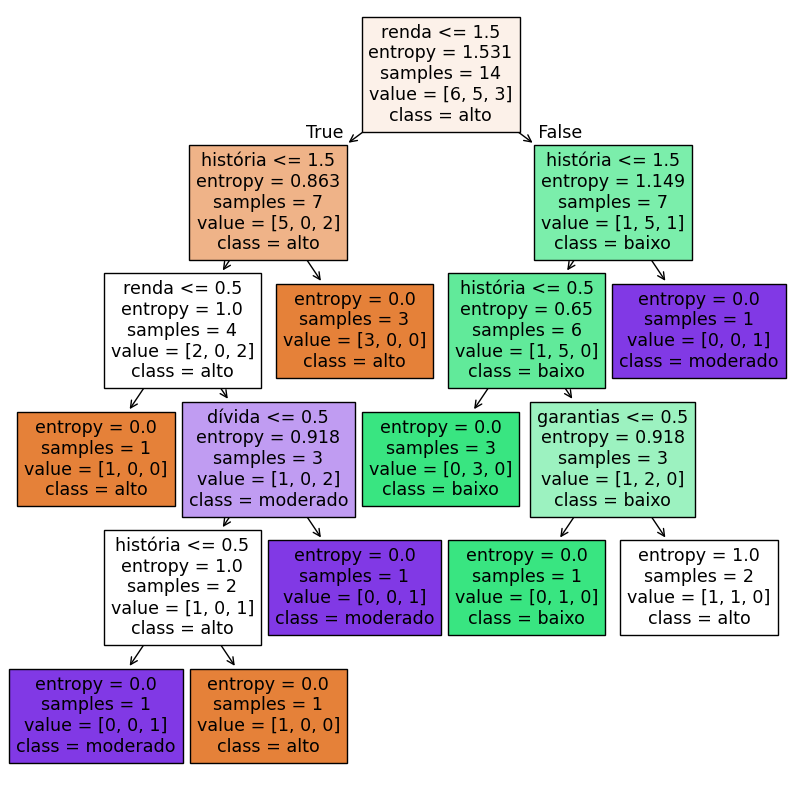

In [6]:
from sklearn import tree
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10,10))
tree.plot_tree(arvore_risco_credito, feature_names=previsores, class_names=arvore_risco_credito.classes_, filled=True)
plt.show()

## e) FAZER A PREVISÃO

i. história boa, dívida alta, garantia nenhuma, renda > 35

ii. história ruim, dívida alta, garantia adequada, renda < 15

In [7]:
previsoes = arvore_risco_credito.predict([[0, 0, 1, 2], [2, 0, 0, 0]])
print(f'Previsão Cenário i: {previsoes[0]}')
print(f'Previsão Cenário ii: {previsoes[1]}')

Previsão Cenário i: baixo
Previsão Cenário ii: alto


# 3 - Algoritmo de Árvore de Decisão para uma base de dados maior (Credit Data)

Nesta seção testamos a Árvore de Decisão na base **Credit Risk Dataset**, analisando clientes que pagam (classe 0) ou não pagam (classe 1) a dívida.

In [8]:
with open('credit.pkl', 'rb') as f:
    X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

## a) Verificar o tamanho dos dados

Os dados de treinamento devem ter: x=(1500, 3), y=(1500,); os dados de teste: x=(500, 3), y=(500,).

In [9]:
print('Dados de treinamento:')
print('X_credit_treinamento:', X_credit_treinamento.shape)
print('y_credit_treinamento:', y_credit_treinamento.shape)
print('Dados de teste:')
print('X_credit_teste:', X_credit_teste.shape)
print('y_credit_teste:', y_credit_teste.shape)

Dados de treinamento:
X_credit_treinamento: (1500, 3)
y_credit_treinamento: (1500,)
Dados de teste:
X_credit_teste: (500, 3)
y_credit_teste: (500,)


## b) Treinar DecisionTreeClassifier com random_state=0

In [10]:
arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_credit_treinamento, y_credit_treinamento)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

## c) Previsão com dados de teste

In [11]:
previsoes_credit = arvore_credit.predict(X_credit_teste)
print('Primeiras 10 previsões:', previsoes_credit[:10])
print('Primeiros 10 valores reais:', y_credit_teste[:10])

Primeiras 10 previsões: [1 0 0 0 0 0 0 0 0 0]
Primeiros 10 valores reais: [1 0 0 0 0 0 0 0 0 0]


## d) Calcular a acurácia

In [12]:
from sklearn.metrics import accuracy_score, classification_report
acuracia_credit = accuracy_score(y_credit_teste, previsoes_credit)
print(f'Acurácia da Árvore de Decisão: {acuracia_credit:.4f} ({acuracia_credit*100:.2f}%)')

Acurácia da Árvore de Decisão: 0.9820 (98.20%)


## e) Análise da Matriz de Confusão

- i. Quantos clientes foram classificados corretamente como pagantes?
- ii. Quantos clientes foram classificados incorretamente como não pagantes?
- iii. Quantos clientes foram classificados corretamente como não pagantes?
- iv. Quantos clientes foram classificados incorretamente como pagantes?

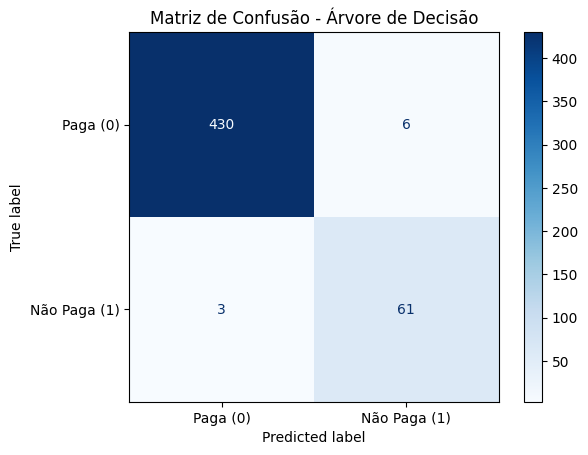

i.  Classificados corretamente como pagantes (TN):          430
ii. Classificados incorretamente como não pagantes (FN):    3
iii.Classificados corretamente como não pagantes (TP):      61
iv. Classificados incorretamente como pagantes (FP):        6


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_matrix = confusion_matrix(y_credit_teste, previsoes_credit)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm_matrix, display_labels=['Paga (0)', 'Não Paga (1)'])
cm_display.plot(cmap='Blues')
plt.title('Matriz de Confusão - Árvore de Decisão')
plt.show()

tn, fp, fn, tp = cm_matrix.ravel()
print(f'i.  Classificados corretamente como pagantes (TN):          {tn}')
print(f'ii. Classificados incorretamente como não pagantes (FN):    {fn}')
print(f'iii.Classificados corretamente como não pagantes (TP):      {tp}')
print(f'iv. Classificados incorretamente como pagantes (FP):        {fp}')

## f) Análise com classification_report

Explique a relação entre precision e recall. Como você interpreta esses dados?

In [14]:
print(classification_report(y_credit_teste, previsoes_credit))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       436
           1       0.91      0.95      0.93        64

    accuracy                           0.98       500
   macro avg       0.95      0.97      0.96       500
weighted avg       0.98      0.98      0.98       500



### Interpretação:

- **Precision**: De todos os casos classificados como classe X, quantos realmente eram X (poucos falsos positivos).
- **Recall**: De todos os casos que realmente eram X, quantos o modelo identificou corretamente (poucos falsos negativos).
- **Classe 0 (pagantes)**: Tende a ter alta precision e recall por ser a classe majoritária.
- **Classe 1 (inadimplentes)**: O recall pode ser menor — o modelo deixa passar inadimplentes, o que tem alto custo para o banco.

## g) Visualização da árvore de decisão

Atributos previsores: ['income', 'age', 'loan']

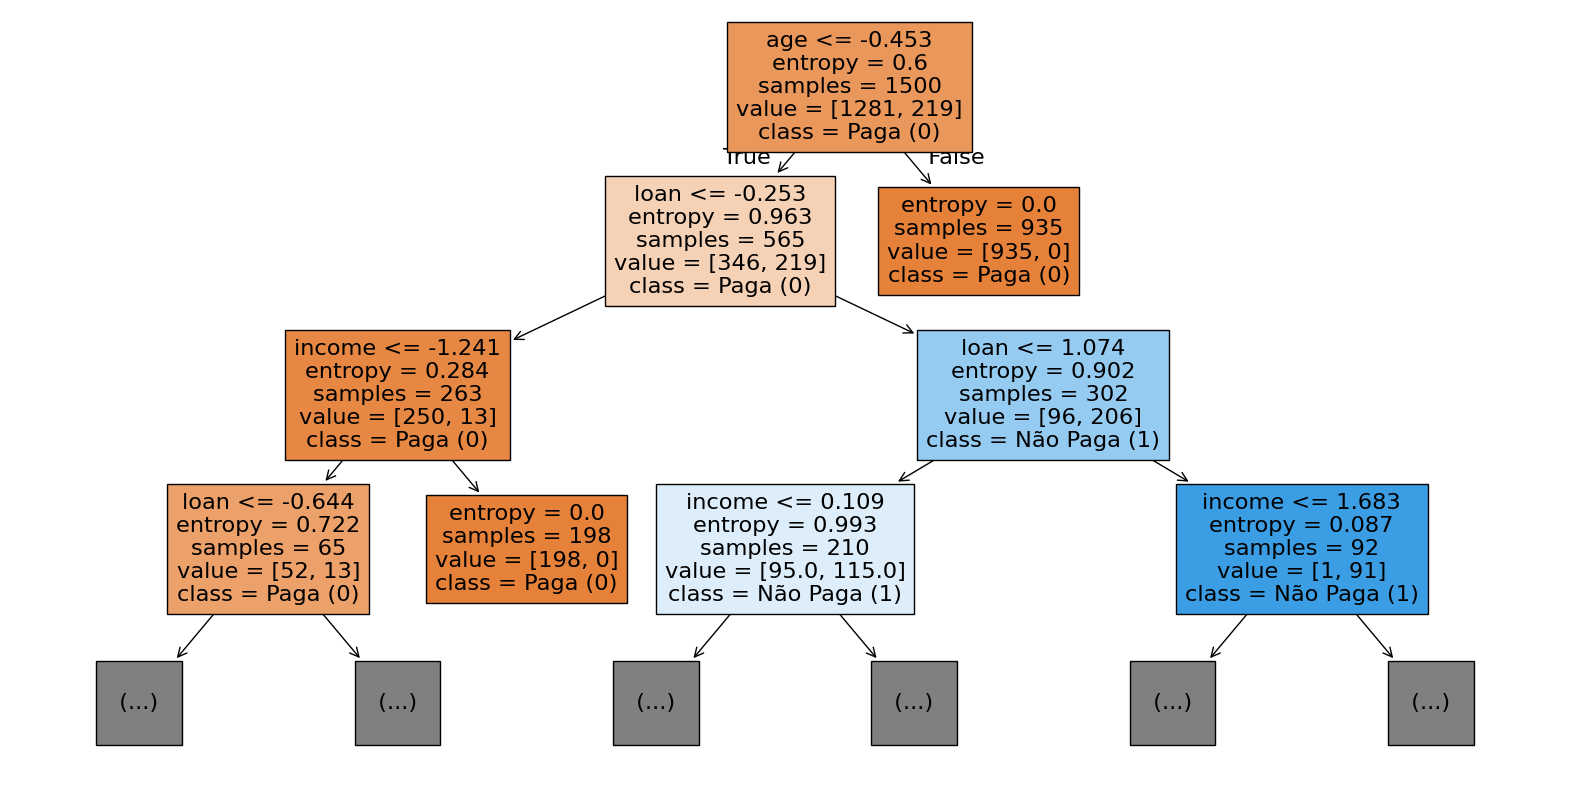

In [15]:
previsores_credit = ['income', 'age', 'loan']
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(20,10))
tree.plot_tree(arvore_credit, feature_names=previsores_credit,
               class_names=['Paga (0)', 'Não Paga (1)'],
               filled=True, max_depth=3)
fig.savefig('arvore_credit.png', dpi=100, bbox_inches='tight')
plt.show()

# Algoritmo Random Forest

Nesta seção iremos utilizar o algoritmo Random Forest para a mesma base de crédito (**Credit Risk Dataset**) — arquivo *credit.pkl*.

## a) Importar RandomForestClassifier do sklearn

In [16]:
from sklearn.ensemble import RandomForestClassifier

## b) Treinar o Random Forest

Parâmetros:
- `n_estimators=10` → número de árvores criadas
- `criterion='entropy'`
- `random_state=0`

In [17]:
random_forest_credit = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
random_forest_credit.fit(X_credit_treinamento, y_credit_treinamento)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metr

## c) Previsão com dados de teste

In [18]:
previsoes_rf = random_forest_credit.predict(X_credit_teste)
print('Primeiras 10 previsões RF:', previsoes_rf[:10])
print('Primeiros 10 valores reais:', y_credit_teste[:10])

Primeiras 10 previsões RF: [1 0 0 0 0 0 0 0 0 0]
Primeiros 10 valores reais: [1 0 0 0 0 0 0 0 0 0]


## d) Calcular acurácia — resultado melhor do que a árvore de decisão simples?

In [19]:
acuracia_rf = accuracy_score(y_credit_teste, previsoes_rf)
print(f'Acurácia Random Forest (10 árvores): {acuracia_rf:.4f} ({acuracia_rf*100:.2f}%)')
print(f'Acurácia Árvore de Decisão:           {acuracia_credit:.4f} ({acuracia_credit*100:.2f}%)')
if acuracia_rf > acuracia_credit:
    print('O Random Forest obteve resultado MELHOR que a árvore simples.')
else:
    print('O Random Forest obteve resultado IGUAL ou INFERIOR à árvore simples.')

Acurácia Random Forest (10 árvores): 0.9680 (96.80%)
Acurácia Árvore de Decisão:           0.9820 (98.20%)
O Random Forest obteve resultado IGUAL ou INFERIOR à árvore simples.


## e) Se o resultado foi inferior, como resolver?

Caso o Random Forest com 10 árvores tenha desempenho inferior ou igual, aumentamos `n_estimators` e testamos o impacto na acurácia.

In [20]:
resultados = {}
for n in [10, 40, 100, 200]:
    rf_tmp = RandomForestClassifier(n_estimators=n, criterion='entropy', random_state=0)
    rf_tmp.fit(X_credit_treinamento, y_credit_treinamento)
    prev_tmp = rf_tmp.predict(X_credit_teste)
    acc = accuracy_score(y_credit_teste, prev_tmp)
    resultados[n] = acc
    print(f'n_estimators={n:3d}: acurácia = {acc:.4f} ({acc*100:.2f}%)')

melhor_n = max(resultados, key=resultados.get)
print(f'Melhor resultado: n_estimators={melhor_n} com acurácia {resultados[melhor_n]:.4f}')

n_estimators= 10: acurácia = 0.9680 (96.80%)
n_estimators= 40: acurácia = 0.9840 (98.40%)


n_estimators=100: acurácia = 0.9820 (98.20%)


n_estimators=200: acurácia = 0.9820 (98.20%)
Melhor resultado: n_estimators=40 com acurácia 0.9840


## f) Análise da Matriz de Confusão

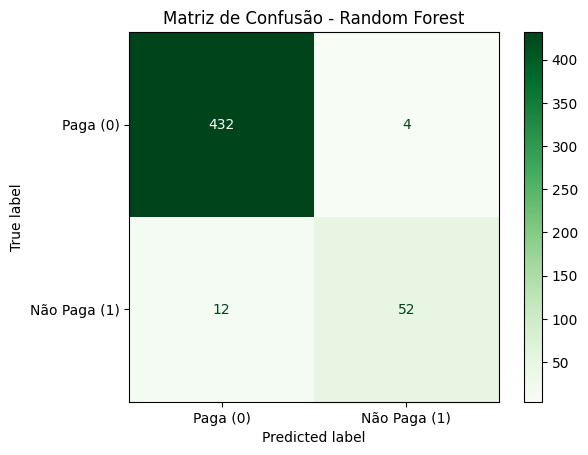

i.  Classificados corretamente como pagantes (TN):          432
ii. Classificados incorretamente como não pagantes (FN):    12
iii.Classificados corretamente como não pagantes (TP):      52
iv. Classificados incorretamente como pagantes (FP):        4


In [21]:
cm_rf_matrix = confusion_matrix(y_credit_teste, previsoes_rf)
cm_rf_display = ConfusionMatrixDisplay(confusion_matrix=cm_rf_matrix, display_labels=['Paga (0)', 'Não Paga (1)'])
cm_rf_display.plot(cmap='Greens')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf_matrix.ravel()
print(f'i.  Classificados corretamente como pagantes (TN):          {tn_rf}')
print(f'ii. Classificados incorretamente como não pagantes (FN):    {fn_rf}')
print(f'iii.Classificados corretamente como não pagantes (TP):      {tp_rf}')
print(f'iv. Classificados incorretamente como pagantes (FP):        {fp_rf}')

## g) classification_report e relação Precision × Recall

Explique a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [22]:
print(classification_report(y_credit_teste, previsoes_rf))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       436
           1       0.93      0.81      0.87        64

    accuracy                           0.97       500
   macro avg       0.95      0.90      0.92       500
weighted avg       0.97      0.97      0.97       500



### Interpretação (Random Forest):

- O **Random Forest** combina múltiplas árvores de decisão, cada uma treinada com amostragem bootstrap e subconjunto aleatório de atributos. A classe final é decidida por **votação majoritária**.

- **Precision vs Recall**:
  - **Classe 0 (pagantes)**: Alta precision e recall são esperados, pois é a classe majoritária — o modelo tem mais exemplos para aprender.
  - **Classe 1 (inadimplentes)**: Se o recall é baixo, o modelo deixa passar inadimplentes (alto custo para o banco). Aumentar `n_estimators` e balancear as classes pode melhorar esse resultado.

- O Random Forest é mais robusto que a árvore simples pois reduz o **overfitting** ao agregar múltiplas árvores com diversidade introduzida pela amostragem aleatória.